# Is Delhi's air quality deteriorating faster than other Indian cities?
**Data:** `city_day.csv` (Kaggle, Air Quality Data in India), 26 cities, 2015 to mid-2020
**Method:** separate trend from seasonality with STL decomposition, then compare Delhi with peer cities.

Put `city_day.csv` in a `data/` folder next to this notebook. Replace each **Finding:** line with one sentence and a number.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import theilslopes, kendalltau
from statsmodels.tsa.seasonal import STL

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

## 1. Load and inspect

In [36]:
df = pd.read_csv(r"C:\Users\Sri Gowrav Srinivas\Downloads\archive\city_day.csv", parse_dates=["Date"])
df["City"] = df["City"].str.strip()
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

print(df.shape, df["Date"].min().date(), df["Date"].max().date(), df["City"].nunique(), "cities")
print("Duplicate city-days:", df.duplicated(["City", "Date"]).sum())
df.head()

(29531, 18) 2015-01-01 2020-07-01 26 cities
Duplicate city-days: 0


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN,2015,1
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN,2015,1
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN,2015,1
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN,2015,1
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN,2015,1


## 2. Data completeness and the fair-comparison set
**Question:** which cities have enough AQI data to compare fairly?

Missing readings stay as NaN (not 0). A city-month counts only if it has at least 20 valid AQI days.

In [37]:
missing_share = df.groupby("City")["AQI"].apply(lambda s: s.isna().mean()).sort_values(ascending=False)
print(missing_share.round(3))

City
Mumbai                0.614
Jorapokhar            0.340
Shillong              0.339
Ahmedabad             0.336
Talcher               0.245
Brajrajnagar          0.240
Patna                 0.215
Visakhapatnam         0.199
Gurugram              0.135
Amaravati             0.116
Coimbatore            0.109
Amritsar              0.078
Kolkata               0.074
Hyderabad             0.063
Chennai               0.062
Lucknow               0.058
Ernakulam             0.056
Thiruvananthapuram    0.054
Bengaluru             0.049
Bhopal                0.038
Kochi                 0.025
Jaipur                0.018
Aizawl                0.018
Chandigarh            0.016
Guwahati              0.014
Delhi                 0.005
Name: AQI, dtype: float64


In [38]:
# valid AQI days per city-month; keep months with at least 20
valid_days = df.groupby(["City", pd.Grouper(key="Date", freq="MS")])["AQI"].count().unstack(0)
valid = valid_days >= 20

coverage = valid.mean().sort_values()          # share of months with enough data
core_cities = coverage[coverage >= 0.80].index.tolist()
print("Core cities:", len(core_cities), "| Delhi included:", "Delhi" in core_cities)
print("Excluded:", [c for c in coverage.index if c not in core_cities])

Core cities: 5 | Delhi included: True
Excluded: ['Aizawl', 'Ernakulam', 'Kochi', 'Shillong', 'Bhopal', 'Chandigarh', 'Coimbatore', 'Guwahati', 'Brajrajnagar', 'Talcher', 'Kolkata', 'Jorapokhar', 'Mumbai', 'Amaravati', 'Thiruvananthapuram', 'Jaipur', 'Amritsar', 'Visakhapatnam', 'Ahmedabad', 'Gurugram', 'Patna']


In [39]:
span = df.groupby("City")["Date"].agg(first="min", last="max")
span["months_available"] = valid.sum()
span["months_possible"] = ((span["last"].dt.year - span["first"].dt.year) * 12
                           + span["last"].dt.month - span["first"].dt.month + 1)
span["pct_of_own_span"] = (span["months_available"] / span["months_possible"]).round(2)
span.sort_values("first")

,first,last,months_available,months_possible,pct_of_own_span
City,,,,,
Ahmedabad,2015-01-01,2020-07-01,45,67,0.67
Mumbai,2015-01-01,2020-07-01,26,67,0.39
Lucknow,2015-01-01,2020-07-01,62,67,0.93
Bengaluru,2015-01-01,2020-07-01,63,67,0.94
Delhi,2015-01-01,2020-07-01,66,67,0.99
Chennai,2015-01-01,2020-07-01,61,67,0.91
Hyderabad,2015-01-04,2020-07-01,62,67,0.93
Patna,2015-06-01,2020-07-01,49,62,0.79
Gurugram,2015-11-27,2020-07-01,48,57,0.84


In [40]:
# Trend set: at least 36 valid months and 75% coverage of the city's own active period
trend_set = span[(span["months_available"] >= 36) & (span["pct_of_own_span"] >= 0.75)].index.tolist()
print(len(trend_set), "cities:", trend_set)

# Rebuild the monthly series for ALL cities (Section 3 overwrote `monthly` with the 5-city subset)
monthly_all = (df.groupby(["City", pd.Grouper(key="Date", freq="MS")])["AQI"]
                 .mean().unstack(0).where(valid))

10 cities: ['Amritsar', 'Bengaluru', 'Chennai', 'Delhi', 'Gurugram', 'Hyderabad', 'Jaipur', 'Lucknow', 'Patna', 'Visakhapatnam']


## 3. Delhi vs the other cities, month by month
**Question:** is the gap between Delhi and the typical city widening?

The ratio (Delhi / median of the other core cities) is the key metric, because it stays flat if everyone worsens together.

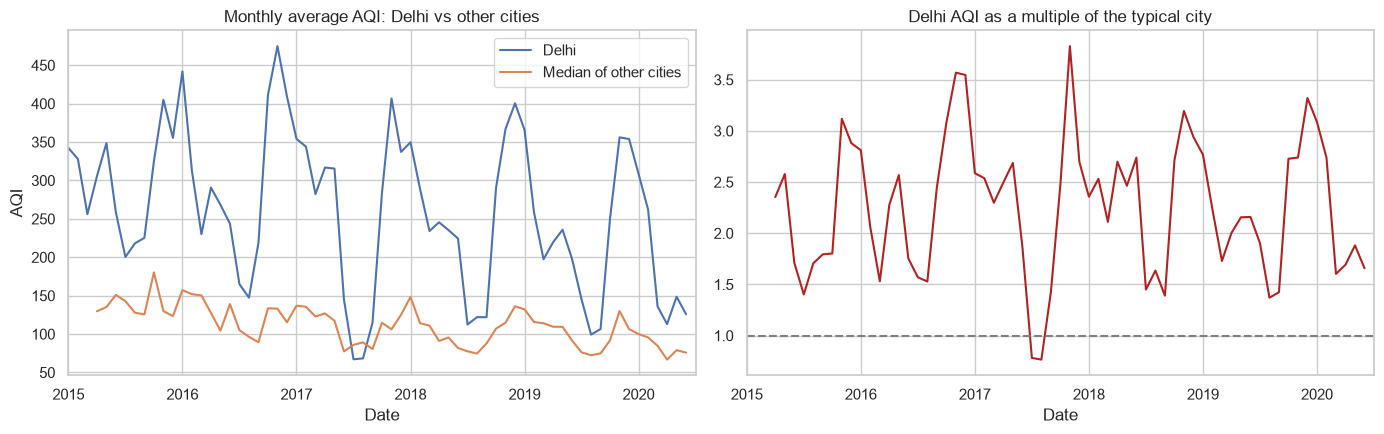

In [41]:
monthly = df.groupby(["City", pd.Grouper(key="Date", freq="MS")])["AQI"].mean().unstack(0)
monthly = monthly.where(valid)[core_cities]     # drop thin months, keep core cities

delhi = monthly["Delhi"]
others = monthly.drop(columns="Delhi").median(axis=1)
gap = delhi - others
ratio = delhi / others

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
delhi.plot(ax=ax[0], label="Delhi")
others.plot(ax=ax[0], label="Median of other cities")
ax[0].set_title("Monthly average AQI: Delhi vs other cities")
ax[0].set_ylabel("AQI")
ax[0].legend()
ratio.plot(ax=ax[1], color="firebrick")
ax[1].axhline(1, color="grey", ls="--")
ax[1].set_title("Delhi AQI as a multiple of the typical city")
plt.tight_layout()
plt.show()

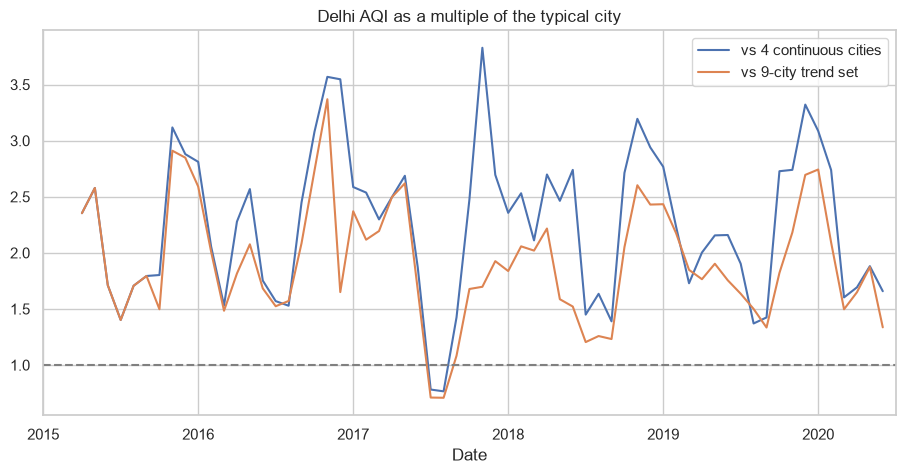

In [42]:
bench_wide = monthly_all[[c for c in trend_set if c != "Delhi"]].median(axis=1)
ratio_wide = monthly_all["Delhi"] / bench_wide

ax = ratio.plot(label="vs 4 continuous cities")
ratio_wide.plot(ax=ax, label="vs 9-city trend set")
ax.axhline(1, color="grey", ls="--")
ax.set_title("Delhi AQI as a multiple of the typical city")
ax.legend()
plt.show()

In [43]:
print("Median ratio, all months:", round(ratio.median(), 2))
print("\nMedian ratio by year:")
print(ratio.groupby(ratio.index.year).median().round(2))

winter_r = ratio[ratio.index.month.isin([11, 12, 1])]
monsoon_r = ratio[ratio.index.month.isin([7, 8, 9])]
print("\nWinter (Nov-Jan) median:", round(winter_r.median(), 2))
print("Monsoon (Jul-Sep) median:", round(monsoon_r.median(), 2))

Median ratio, all months: 2.3

Median ratio by year:
Date
2015    1.80
2016    2.36
2017    2.49
2018    2.50
2019    2.16
2020    1.79
dtype: float64

Winter (Nov-Jan) median: 2.94
Monsoon (Jul-Sep) median: 1.45


## 4. Rolling averages
**Question:** does the long-run level move once seasonality is smoothed out?

A 365-day rolling mean spans a full cycle, so it removes seasonality by construction.

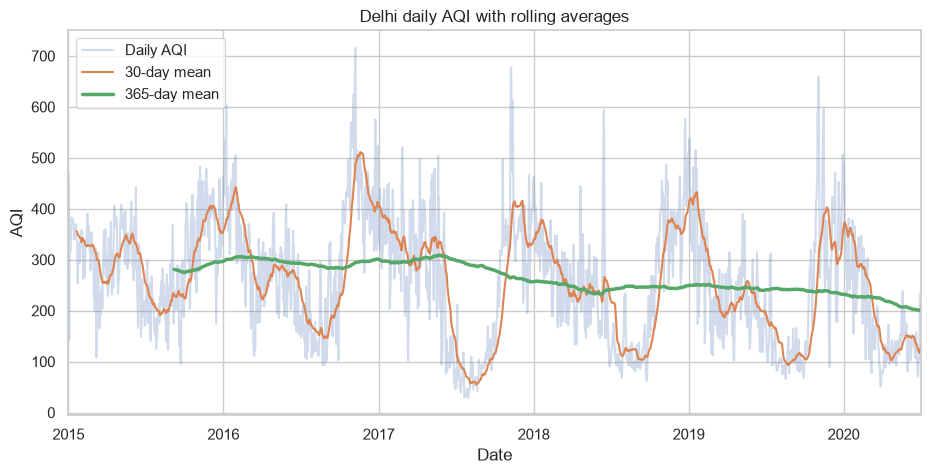

In [44]:
daily = df[df["City"] == "Delhi"].set_index("Date")["AQI"].asfreq("D")
roll30 = daily.rolling(30, min_periods=20).mean()
roll365 = daily.rolling(365, min_periods=250).mean()

ax = daily.plot(alpha=0.25, label="Daily AQI")
roll30.plot(ax=ax, label="30-day mean")
roll365.plot(ax=ax, lw=2.5, label="365-day mean")
ax.set_title("Delhi daily AQI with rolling averages")
ax.set_ylabel("AQI")
ax.legend()
plt.show()

In [45]:
r = roll365.dropna()
print("365-day mean at the end of each year:")
print(r.groupby(r.index.year).last().round(0))
print("\nHighest:", round(r.max()), "on", r.idxmax().date())
print("Lowest: ", round(r.min()), "on", r.idxmin().date())

print("\nFull-year average AQI:")
print(daily.groupby(daily.index.year).mean().round(0))

365-day mean at the end of each year:
Date
2015    297.0
2016    301.0
2017    257.0
2018    249.0
2019    232.0
2020    200.0
Name: AQI, dtype: float64

Highest: 309 on 2017-05-24
Lowest:  200 on 2020-07-01

Full-year average AQI:
Date
2015    297.0
2016    301.0
2017    257.0
2018    249.0
2019    232.0
2020    182.0
Name: AQI, dtype: float64


## 5. Trend vs seasonality (STL decomposition)
**Question:** after removing the seasonal cycle, is Delhi's AQI trending up, flat or down?

Months: 66 | Still missing: 0


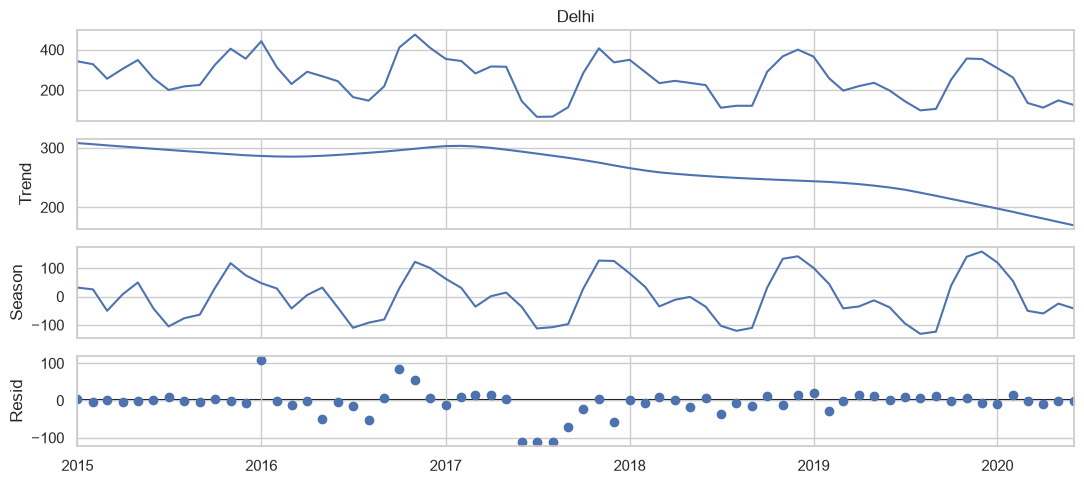

In [46]:
# fill gaps of up to 2 months inside the series, then trim to the valid range
s = delhi.interpolate(limit=2, limit_area="inside")
s = s.loc[s.first_valid_index():s.last_valid_index()]
print("Months:", len(s), "| Still missing:", int(s.isna().sum()))   # must be 0 for STL

res = STL(s, period=12, robust=True).fit()
res.plot()
plt.show()

In [47]:
seas = res.seasonal
print("Trend: start", round(res.trend.iloc[0]),
      "| end of 2019", round(res.trend[:"2019-12-31"].iloc[-1]),
      "| end", round(res.trend.iloc[-1]))
print("\nSeasonal swing by year (max / min):")
print(seas.groupby(seas.index.year).agg(["max", "min"]).round(0))
print("\nLargest residuals (beyond ±60):")
print(res.resid[res.resid.abs() > 60].round(0))

Trend: start 308 | end of 2019 203 | end 169

Seasonal swing by year (max / min):
        max    min
Date              
2015  117.0 -105.0
2016  122.0 -110.0
2017  127.0 -112.0
2018  141.0 -121.0
2019  158.0 -131.0
2020  120.0  -60.0

Largest residuals (beyond ±60):
Date
2016-01-01    109.0
2016-10-01     86.0
2017-06-01   -112.0
2017-07-01   -111.0
2017-08-01   -111.0
2017-09-01    -72.0
Name: resid, dtype: float64


In [48]:
def trend_per_year(series):
    # Theil-Sen slope of the STL trend, in AQI points per year (robust to outliers)
    tr = STL(series, period=12, robust=True).fit().trend.dropna()
    t = np.arange(len(tr))
    slope, _, lo, hi = theilslopes(tr.values, t)
    return slope * 12, lo * 12, hi * 12

slope, lo, hi = trend_per_year(s)
print(f"Delhi trend: {slope:.1f} AQI points/year (95% interval {lo:.1f} to {hi:.1f})")

tr = res.trend.dropna()
tau, p = kendalltau(np.arange(len(tr)), tr.values)
print(f"Kendall tau = {tau:.2f}, p-value = {p:.3g}")

# robustness check: exclude 2020 (lockdown months)
slope_x, lo_x, hi_x = trend_per_year(s[s.index < "2020-01-01"])
print(f"Excluding 2020: {slope_x:.1f} points/year (95% interval {lo_x:.1f} to {hi_x:.1f})")

Delhi trend: -21.3 AQI points/year (95% interval -23.9 to -18.2)
Kendall tau = -0.80, p-value = 2.54e-21
Excluding 2020: -16.8 points/year (95% interval -18.0 to -15.9)


**Finding:** (state plainly if the interval includes zero)

## 6. Trend for every core city
**Question:** which cities are deteriorating faster than Delhi, and which are improving?

In [49]:
rows2 = []
for city in trend_set:
    sc = monthly_all[city].interpolate(limit=3, limit_area="inside")
    sc = sc.loc[sc.first_valid_index():sc.last_valid_index()]
    if sc.isna().any():
        print("Skipped (gap longer than 3 months):", city)
        continue
    sl, lo, hi = trend_per_year(sc)
    pre = sc[sc.index < "2020-01-01"]
    sl_x = trend_per_year(pre)[0] if len(pre) >= 24 else np.nan
    rows2.append({"City": city,
                  "slope_per_year": sl, "ci_low": lo, "ci_high": hi,
                  "slope_excl_2020": sl_x,
                  "pct_of_mean_per_year": 100 * sl / sc.mean(),
                  "months": len(sc), "starts": sc.index[0].date()})

trends2 = pd.DataFrame(rows2).sort_values("slope_per_year", ascending=False).reset_index(drop=True)
print(trends2.columns.tolist())
trends2.round(2)

Skipped (gap longer than 3 months): Patna
Skipped (gap longer than 3 months): Visakhapatnam
['City', 'slope_per_year', 'ci_low', 'ci_high', 'slope_excl_2020', 'pct_of_mean_per_year', 'months', 'starts']


,City,slope_per_year,ci_low,ci_high,slope_excl_2020,pct_of_mean_per_year,months,starts
0,Lucknow,-5.40,-10.25,-3.83,-3.14,-2.49,63,2015-04-01
1,Bengaluru,-7.48,-9.27,-6.05,-4.19,-7.96,63,2015-04-01
2,Chennai,-10.33,-12.45,-8.93,-11.38,-9.04,63,2015-04-01
3,Hyderabad,-13.22,-14.28,-12.18,-14.16,-12.10,63,2015-04-01
4,Delhi,-21.34,-23.94,-18.20,-16.75,-8.24,66,2015-01-01
5,Amritsar,-21.56,-30.71,-19.46,-24.27,-18.07,40,2017-03-01
6,Gurugram,-26.80,-30.24,-21.71,-21.27,-12.05,51,2016-04-01
7,Jaipur,-27.07,-27.32,-26.82,-29.35,-20.20,36,2017-07-01


In [50]:
trends = pd.DataFrame(rows2).sort_values("slope_per_year", ascending=False).reset_index(drop=True)
print(trends.columns.tolist())
trends.round(2)

['City', 'slope_per_year', 'ci_low', 'ci_high', 'slope_excl_2020', 'pct_of_mean_per_year', 'months', 'starts']


,City,slope_per_year,ci_low,ci_high,slope_excl_2020,pct_of_mean_per_year,months,starts
0,Lucknow,-5.40,-10.25,-3.83,-3.14,-2.49,63,2015-04-01
1,Bengaluru,-7.48,-9.27,-6.05,-4.19,-7.96,63,2015-04-01
2,Chennai,-10.33,-12.45,-8.93,-11.38,-9.04,63,2015-04-01
3,Hyderabad,-13.22,-14.28,-12.18,-14.16,-12.10,63,2015-04-01
4,Delhi,-21.34,-23.94,-18.20,-16.75,-8.24,66,2015-01-01
5,Amritsar,-21.56,-30.71,-19.46,-24.27,-18.07,40,2017-03-01
6,Gurugram,-26.80,-30.24,-21.71,-21.27,-12.05,51,2016-04-01
7,Jaipur,-27.07,-27.32,-26.82,-29.35,-20.20,36,2017-07-01


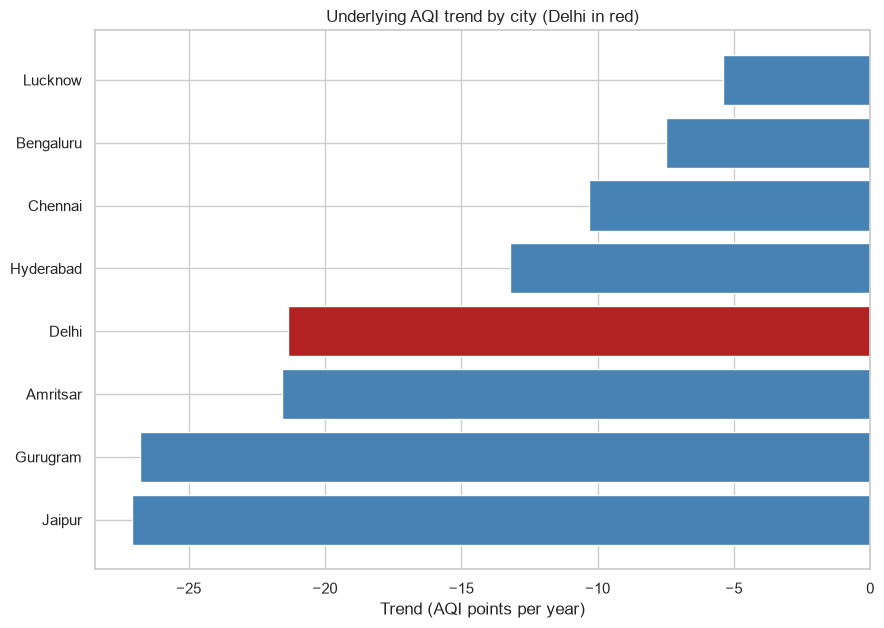

In [51]:
colors = ["firebrick" if c == "Delhi" else "steelblue" for c in trends["City"]]
plt.figure(figsize=(10, 7))
plt.barh(trends["City"], trends["slope_per_year"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
plt.xlabel("Trend (AQI points per year)")
plt.title("Underlying AQI trend by city (Delhi in red)")
plt.show()

## 7. Gap trend, winter peaks and severe days
**Questions:** is the Delhi-minus-others gap widening? Are winter peaks and Very Poor / Severe days increasing?

In [52]:
# trend of the Delhi / others gap
g = gap.interpolate(limit=2, limit_area="inside")
g = g.loc[g.first_valid_index():g.last_valid_index()]
gs, glo, ghi = trend_per_year(g)
print(f"Gap trend: {gs:.1f} AQI points/year (95% interval {glo:.1f} to {ghi:.1f})")

Gap trend: -16.4 AQI points/year (95% interval -22.6 to -11.3)


In [53]:
w = df[(df["City"] == "Delhi") & (df["Month"].isin([11, 12, 1]))].copy()
w["start"] = np.where(w["Month"] == 1, w["Year"] - 1, w["Year"])
w["Season"] = w["start"].astype(str) + "-" + (w["start"] + 1).astype(str).str[-2:]
w.groupby("Season")["AQI"].agg(mean="mean", max="max", days="count").round(1)

,mean,max,days
Season,,,
2014-15,342.3,472.0,31
2015-16,400.7,603.0,92
2016-17,412.1,716.0,92
2017-18,364.1,677.0,92
2018-19,377.8,577.0,92
2019-20,339.3,659.0,92


In [54]:
bad = (df[df["City"] == "Delhi"]
       .assign(bad=lambda d: d["AQI_Bucket"].isin(["Very Poor", "Severe"]))
       .groupby("Year")
       .agg(bad_days=("bad", "sum"), days_with_aqi=("AQI", "count")))
bad["pct_bad_days"] = (100 * bad["bad_days"] / bad["days_with_aqi"]).round(1)
bad

,bad_days,days_with_aqi,pct_bad_days
Year,,,
2015,183,365,50.1
2016,173,365,47.4
2017,163,356,45.8
2018,120,365,32.9
2019,95,365,26.0
2020,25,183,13.7


In [55]:
d = df[df["City"] == "Delhi"].assign(bad=lambda x: x["AQI_Bucket"].isin(["Very Poor", "Severe"]))
d.pivot_table(index="Month", columns="Year", values="bad", aggfunc="sum")

Year,2015,2016,2017,2018,2019,2020
Month,,,,,,
1,27.0,31.0,26.0,24.0,24.0,15.0
2,24.0,19.0,22.0,14.0,11.0,10.0
3,8.0,6.0,13.0,3.0,0.0,0.0
4,14.0,12.0,14.0,5.0,1.0,0.0
5,25.0,10.0,17.0,4.0,6.0,0.0
6,7.0,6.0,4.0,5.0,1.0,0.0
7,0.0,0.0,0.0,0.0,1.0,0.0
8,0.0,0.0,0.0,0.0,0.0,NaN
9,2.0,2.0,0.0,0.0,0.0,NaN


      Nov-Jan  Feb-Oct
Year                  
2015     84.0     99.0
2016     91.0     82.0
2017     75.0     88.0
2018     76.0     44.0
2019     66.0     29.0


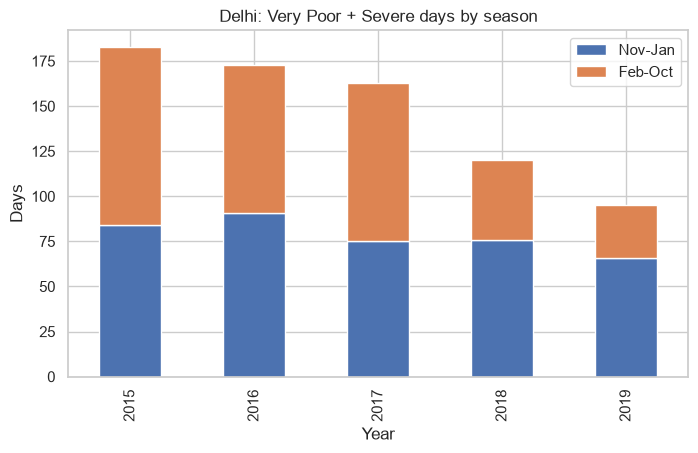

In [56]:
piv = d.pivot_table(index="Month", columns="Year", values="bad", aggfunc="sum")
winter_bad = piv.loc[[11, 12, 1]].sum()
split = pd.DataFrame({"Nov-Jan": winter_bad, "Feb-Oct": piv.sum() - winter_bad}).loc[2015:2019]
print(split)
split.plot(kind="bar", stacked=True, figsize=(8, 4.5),
           title="Delhi: Very Poor + Severe days by season")
plt.ylabel("Days")
plt.show()

**Finding:** (2020 is a partial year, so compare shares, not counts)

## 8. Seasonal pattern and city heatmap
**Question:** does Delhi follow the same seasonal shape as other north Indian cities?

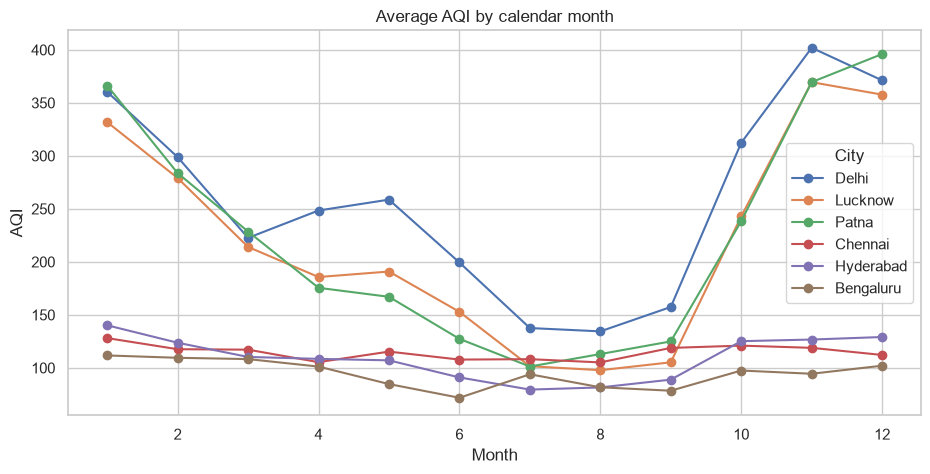

In [57]:
profile = df.groupby(["City", "Month"])["AQI"].mean().unstack(0)
north = [c for c in ["Delhi", "Lucknow", "Patna"] if c in profile]
south = [c for c in ["Chennai", "Hyderabad", "Bengaluru"] if c in profile]
profile[north + south].plot(marker="o")
plt.title("Average AQI by calendar month")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.show()

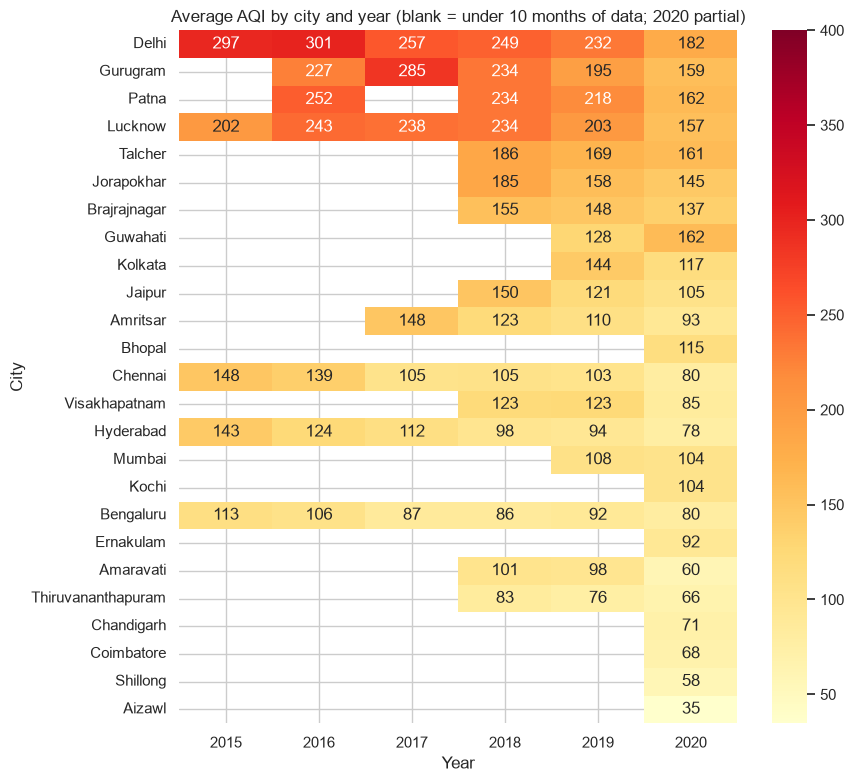

In [58]:
valid_aqi = df.dropna(subset=["AQI"])
months = valid_aqi.groupby(["City", "Year"])["Date"].apply(lambda s: s.dt.month.nunique()).unstack()
avg = (valid_aqi.pivot_table(index="City", columns="Year", values="AQI", aggfunc="mean")
                .drop(index="Ahmedabad"))
thin = months.reindex_like(avg) < 10
thin[2020] = False                       # 2020 is partial for everyone; stated in the title
avg = avg.mask(thin)
order = avg.mean(axis=1).sort_values(ascending=False).index

plt.figure(figsize=(9, 9))
sns.heatmap(avg.loc[order], annot=True, fmt=".0f", cmap="YlOrRd", vmax=400)
plt.title("Average AQI by city and year (blank = under 10 months of data; 2020 partial)")
plt.show()

In [59]:
a = df.loc[df["City"] == "Ahmedabad", "AQI"]
print(a.describe().round(0))
print("Days above 500:", (a > 500).sum(), "of", a.notna().sum())

count    1334.0
mean      452.0
std       312.0
min        48.0
25%       231.0
50%       384.0
75%       543.0
max      2049.0
Name: AQI, dtype: float64
Days above 500: 412 of 1334


In [60]:
v = df.dropna(subset=["AQI"])
(v.assign(over500=v["AQI"] > 500).groupby("City")["over500"].mean()
   .mul(100).round(1).sort_values(ascending=False).head(8))

City
Ahmedabad     30.9
Delhi          2.4
Patna          1.7
Gurugram       1.5
Jorapokhar     0.9
Lucknow        0.8
Talcher        0.6
Guwahati       0.4
Name: over500, dtype: float64

## 9. Pollutant drivers
**Questions:** which pollutant drives Delhi's AQI, and does Delhi's mix differ from other cities?

In [61]:
pollutants = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]
delhi_p = df[df["City"] == "Delhi"].groupby("Year")[pollutants].mean().round(1)
others_p = df[df["City"] != "Delhi"].groupby("Year")[pollutants].mean().round(1)

print("Delhi, yearly mean"); display(delhi_p)
print("Other cities, yearly mean"); display(others_p)

corr = (df[df["City"] == "Delhi"][pollutants + ["AQI"]].corr()["AQI"]
        .drop("AQI").sort_values(ascending=False).round(2))
print("Correlation with AQI (Delhi):"); print(corr)

Delhi, yearly mean


,PM2.5,PM10,NO2,CO,SO2,O3
Year,,,,,,
2015,117.3,230.0,50.4,5.3,12.6,57.4
2016,138.5,258.3,63.5,1.6,18.8,76.9
2017,125.1,264.4,57.7,0.7,23.8,42.2
2018,115.0,240.1,45.9,1.4,13.6,44.4
2019,108.5,215.0,45.2,1.4,14.0,38.9
2020,80.3,157.0,33.2,1.1,13.9,40.6


Other cities, yearly mean


,PM2.5,PM10,NO2,CO,SO2,O3
Year,,,,,,
2015,75.0,83.8,18.8,4.0,13.7,28.4
2016,84.8,95.2,26.3,1.8,8.7,31.8
2017,81.2,105.2,28.9,1.3,11.3,33.7
2018,66.0,123.3,32.5,3.1,18.5,34.6
2019,56.3,106.5,27.6,2.3,16.5,32.7
2020,42.4,86.8,20.0,1.2,11.8,34.4


Correlation with AQI (Delhi):
PM10     0.88
PM2.5    0.88
NO2      0.67
SO2      0.41
O3       0.33
CO       0.28
Name: AQI, dtype: float64


## 10. Lockdown and Diwali
**Questions:** how much did the 2020 lockdown cut AQI in Delhi vs other cities? What is the Diwali effect?

Lockdown window: 25 Mar to 30 Jun, compared with the same dates in 2019.

In [62]:
def window_mean(year):
    m = df[(df["Date"] >= f"{year}-03-25") & (df["Date"] <= f"{year}-06-30")]
    return m.groupby("City")["AQI"].mean()

lock = pd.DataFrame({"aqi_2019": window_mean(2019), "aqi_2020": window_mean(2020)}).dropna()
lock["pct_change"] = (100 * (lock["aqi_2020"] - lock["aqi_2019"]) / lock["aqi_2019"]).round(1)
print("Delhi:", lock.loc["Delhi", "pct_change"], "% | median city:", lock["pct_change"].median(), "%")
lock.sort_values("pct_change").round(1)

Delhi: -42.2 % | median city: -29.45 %


,aqi_2019,aqi_2020,pct_change
City,,,
Ahmedabad,500.9,119.9,-76.1
Lucknow,193.3,107.2,-44.6
Delhi,217.0,125.5,-42.2
Gurugram,208.9,126.2,-39.6
Amaravati,81.6,52.1,-36.2
Bengaluru,102.2,65.8,-35.6
Visakhapatnam,106.0,68.9,-35.1
Kolkata,87.0,59.9,-31.2
Hyderabad,93.1,64.2,-31.0


In [63]:
# Diwali dates: verify against a calendar before publishing
diwali = {2015: "2015-11-11", 2016: "2016-10-30", 2017: "2017-10-19",
          2018: "2018-11-07", 2019: "2019-10-27"}
d = df[df["City"] == "Delhi"].set_index("Date")["AQI"]

rows = []
for yr, dt in diwali.items():
    dt = pd.Timestamp(dt)
    around = d[dt - pd.Timedelta(days=3): dt + pd.Timedelta(days=3)].mean()
    before = d[dt - pd.Timedelta(days=24): dt - pd.Timedelta(days=4)].mean()
    rows.append({"year": yr, "before_aqi": before, "diwali_aqi": around,
                 "pct_jump": 100 * (around - before) / before})
pd.DataFrame(rows).round(1)

,year,before_aqi,diwali_aqi,pct_jump
0,2015,357.4,432.0,20.9
1,2016,409.9,552.4,34.8
2,2017,191.2,358.3,87.4
3,2018,350.2,394.1,12.5
4,2019,214.0,374.7,75.1


## 11. Summary of findings

**Answer to the project question:** Delhi's air is far more polluted than most Indian cities, especially in winter, but it is not deteriorating faster than other cities. Between 2015 and 2020, Delhi's underlying AQI fell, the gap with other cities narrowed, and the improvement came mainly outside the winter months.

1. **Trend:** After removing seasonality, Delhi's AQI fell by about 21 points per year (range −24 to −18), or about 17 points per year excluding the 2020 lockdown months. The decline holds with and without 2020.
2. **Winter peaks:** Across five complete winters (2015–16 to 2019–20), Delhi's November to January average AQI ranged from 339 to 412. It peaked in 2016–17 and was lowest in 2019–20. Every winter stayed in the Very Poor range or worse, and daily peaks of 577 to 716 recurred each year.
3. **Severe days:** The share of days rated Very Poor or Severe fell from 50% in 2015 (183 days) to 26% in 2019 (95 days). About 80% of that reduction came outside November to January (February to October fell from 99 to 29 days, while November to January fell from 84 to 66), so winter remains the core problem.
4. **Rank among cities:** Excluding Ahmedabad, and among cities with enough data in each year, Delhi has the highest annual average AQI in every year except 2017, when Gurugram was higher. Delhi's yearly average fell from 301 in 2016 to 232 in 2019 (−23%).
5. **Gap vs other cities:** Delhi's AQI lead over the typical continuously-reporting city is narrowing by about 16 points per year (range −23 to −11). In most months Delhi is 1.5 to 3.5 times the typical city, and it falls close to parity in the monsoon.
6. **Cities deteriorating faster than Delhi:** None. All 8 cities with at least three years of near-continuous data show a falling AQI. Delhi's decline (about 21 points per year) ranks 4th of 8 in absolute terms, behind Jaipur, Gurugram and Amritsar, and about 6th in relative terms (about 8% of its average level per year).
7. **Seasonal pattern vs other cities:** Delhi follows the same U-shaped cycle as Lucknow and Patna, peaking in November to January, while Chennai, Hyderabad and Bengaluru stay flat all year. Delhi's winter peak is similar to its northern peers; it stands out in October and April to June, when it runs well above them.
8. **Main pollutant:** PM2.5 and PM10 track Delhi's AQI most closely (correlation 0.88 each), ahead of NO2 (0.67). In 2019, Delhi's PM2.5 and PM10 were about 1.9 to 2.0 times the average of other cities and NO2 about 1.6 times, while CO and SO2 were no higher. Delhi's PM2.5 fell about 22% between 2016 and 2019.
9. **Lockdown effect:** Between 25 March and 30 June, Delhi's average AQI fell 42% year over year (217 to 126), the second-largest drop among 19 cities, against a median of about 29%. Part of this reflects the ongoing downward trend, not the lockdown alone.
10. **Diwali effect:** In each of 2015 to 2019, Delhi's AQI in the 7 days around Diwali was 13% to 87% higher than in the preceding three weeks. The jump is larger when Diwali falls early in the pollution season, so the figures include the normal autumn rise.
11. **Data completeness:** Delhi has the most complete record (99% of months valid), but coverage is uneven overall: 16 of 26 cities began reporting in 2017 or later, and only 5 have continuous 2015 to 2020 data. Ahmedabad was excluded because 31% of its readings exceed the AQI scale's maximum of 500 (up to 2,049). Patna and Visakhapatnam were left out of the trend ranking because of gaps longer than three months.

**Limitations:**
- Uneven coverage: cities are compared over different periods, and the shorter records (Jaipur, Amritsar, Gurugram) give less reliable trends.
- Only about 5.5 years of data, and 2020 covers only January to June and is distorted by the lockdown.
- Trend intervals are fitted to a smoothed series, so they are more optimistic than they look. Direction and size matter more than the exact range.
- Delhi's average blends several monitoring stations, and changes in which stations report could affect the trend.
- AQI is a derived index (the maximum sub-index), and some readings exceed the official 500 maximum. CO and O3 show jumps that look like measurement changes, so they were not interpreted.

In [65]:
  import os
  os.makedirs("outputs", exist_ok=True)
  monthly_all.drop(columns="Ahmedabad", errors="ignore").to_csv("outputs/monthly_aqi_by_city.csv")
  trends.to_csv("outputs/city_trends.csv", index=False)
  lock.drop(index="Ahmedabad", errors="ignore").to_csv("outputs/lockdown_change.csv")
  bad.to_csv("outputs/delhi_bad_days.csv")